# Education Spending & Outcomes Analysis

**Author:** Juan Diego Leal Salazar
**Date:** October 2026
**Goal:** Analyze historical trends in education spending (% of GDP) across Latin America and build a baseline predictive model.

---

## 1. Data Loading

We will use the **World Bank Open Data API** to fetch the indicator `SE.XPD.TOTL.GD.ZS` (Government expenditure on education, total % of GDP). 

*Why this indicator?* It is a standard metric used by economists to measure a country's investment in education relative to its wealth.

In [2]:
import pandas as pd
import requests

indicator = "SE.XPD.TOTL.GD.ZS"  # Gasto educativo (% del PIB)
url = f"https://api.worldbank.org/v2/country/all/indicator/{indicator}?format=json&per_page=20000"

resp = requests.get(url)
data = resp.json()

print("metadata:", data[0])
print("primer registro:", data[1][0])

metadata: {'page': 1, 'pages': 1, 'per_page': 20000, 'total': 17556, 'sourceid': '2', 'lastupdated': '2026-10-08'}
primer registro: {'indicator': {'id': 'SE.XPD.TOTL.GD.ZS', 'value': 'Government expenditure on education, total (% of GDP)'}, 'country': {'id': 'ZH', 'value': 'Africa Eastern and Southern'}, 'countryiso3code': 'AFE', 'date': '2025', 'value': None, 'unit': '', 'obs_status': '', 'decimal': 1}


## 2. Data Cleaning & Preprocessing

The API returns a nested JSON object. In this step, we extract the country names, the year, and the spending value. We also remove any null values and sort the data chronologically for time-series analysis.

In [3]:
# Convertir los datos a una tabla (DataFrame)
df = pd.DataFrame(data[1])

# Limpiar la columna 'country' para que solo quede el nombre del país
df['country'] = df['country'].apply(lambda x: x['value'])

# Quedarnos solo con las columnas útiles
df = df[['country', 'date', 'value']]

# Quitar filas donde el valor sea nulo (países que no reportaron ese año)
df = df.dropna(subset=['value'])

# Convertir el año a número entero y ordenar
df['date'] = df['date'].astype(int)
df = df.sort_values(['country', 'date'])

# Mostrar las primeras 5 filas
df.head()

,country,date,value
3249,Afghanistan,2010,3.47945
3248,Afghanistan,2011,3.46201
3247,Afghanistan,2012,2.60421
3246,Afghanistan,2013,3.45446
3245,Afghanistan,2014,3.69522


## 3. Exploratory Data Analysis (EDA)

### 3.1 Trend Analysis: Colombia, Chile & Mexico
Let's compare the historical trajectory of education spending for three key Latin American economies. This helps identify if the region follows a common trend or diverges significantly.

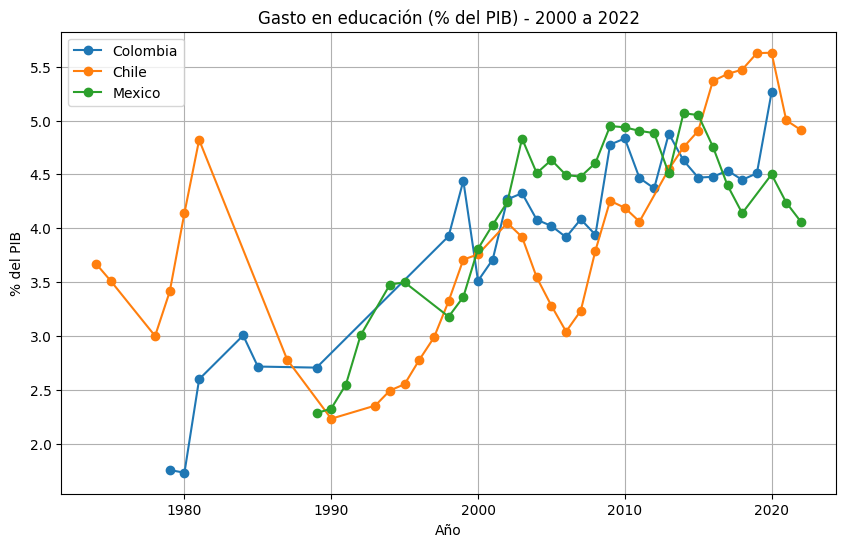

In [4]:
import matplotlib.pyplot as plt
import os

# Filtrar los datos de Colombia, Chile y México
paises = ['Colombia', 'Chile', 'Mexico']
df_filtrado = df[df['country'].isin(paises)]

plt.figure(figsize=(10, 6))

for pais in paises:
    datos_pais = df_filtrado[df_filtrado['country'] == pais]
    plt.plot(datos_pais['date'], datos_pais['value'], label=pais, marker='o')

plt.title('Gasto en educación (% del PIB) - 2000 a 2022')
plt.xlabel('Año')
plt.ylabel('% del PIB')
plt.legend()
plt.grid(True)

# Crear la carpeta 'reports' si no existe y guardar la imagen
os.makedirs('../reports', exist_ok=True)
plt.savefig('../reports/01_education_spending.png', dpi=300, bbox_inches='tight')

# Mostrar la gráfica en pantalla
plt.show()

### 3.2 Regional Heatmap: Latin America
To get a broader perspective, we plot a heatmap of 9 Latin American countries from the year 2000 onwards. Darker colors indicate a higher percentage of GDP spent on education.

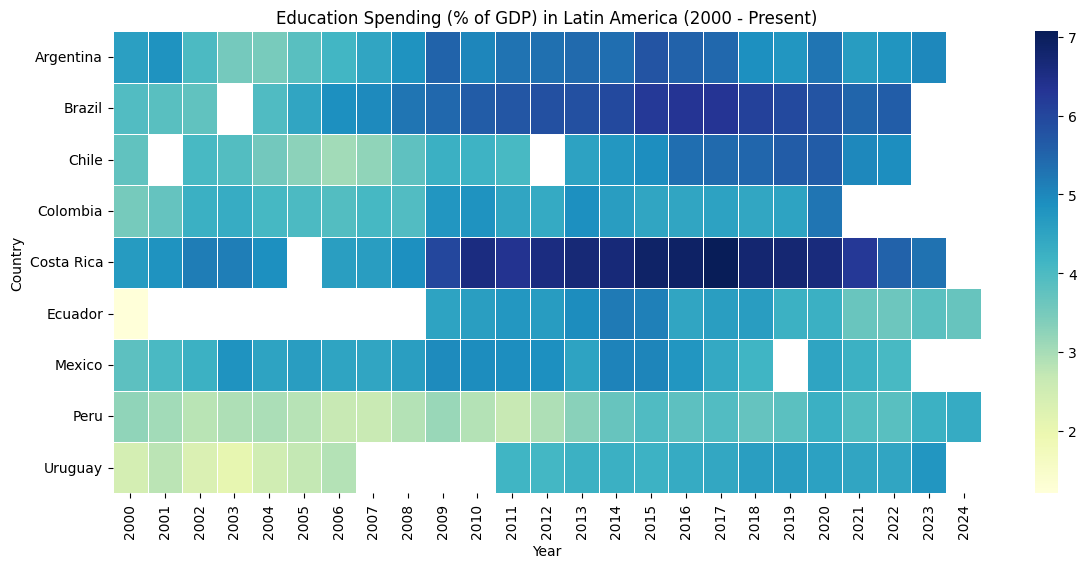

In [5]:
import seaborn as sns

# Lista de países de América Latina (puedes agregar más)
latam = ['Colombia', 'Chile', 'Mexico', 'Brazil', 'Argentina', 'Peru', 'Ecuador', 'Costa Rica', 'Uruguay']
df_latam = df[df['country'].isin(latam)]

# Crear una tabla dinámica: filas = países, columnas = años, valores = % del PIB
pivot_latam = df_latam.pivot(index='country', columns='date', values='value')

# Quedarnos con los años recientes (del 2000 en adelante) para que se vea bien
pivot_latam = pivot_latam.loc[:, pivot_latam.columns >= 2000]

# Crear el mapa de calor
plt.figure(figsize=(14, 6))
sns.heatmap(pivot_latam, cmap='YlGnBu', linewidths=.5, annot=False)
plt.title('Education Spending (% of GDP) in Latin America (2000 - Present)')
plt.xlabel('Year')
plt.ylabel('Country')
plt.show()

## 4. Machine Learning: Predictive Modeling

Can we predict the education spending of a country based on the year? We will train a simple **Linear Regression** model using `scikit-learn` to find the underlying trend. 

We split the data into training (80%) and testing (20%) sets to evaluate performance.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import numpy as np

# Preparar los datos de Colombia
df_col = df[df['country'] == 'Colombia'].dropna(subset=['value'])
X = df_col[['date']]  # El año (variable independiente)
y = df_col['value']   # El gasto (variable dependiente)

# Dividir en datos de entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Crear y entrenar el modelo
model = LinearRegression()
model.fit(X_train, y_train)

# Hacer predicciones
y_pred = model.predict(X_test)

# Calcular el error (MSE)
mse = mean_squared_error(y_test, y_pred)

print(f"Model trained successfully!")
print(f"Mean Squared Error: {mse:.4f}")
print(f"Model coefficient: {model.coef_[0]:.4f} (average change per year)")

Model trained successfully!
Mean Squared Error: 0.0802
Model coefficient: 0.0691 (average change per year)


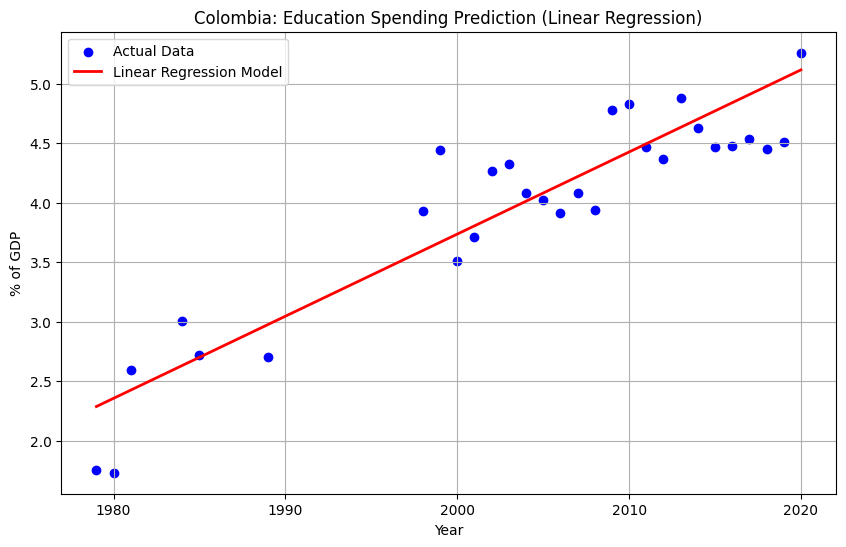

In [7]:
plt.figure(figsize=(10, 6))

# Datos reales
plt.scatter(X, y, color='blue', label='Actual Data')

# Línea de predicción del modelo
plt.plot(X, model.predict(X), color='red', linewidth=2, label='Linear Regression Model')

plt.title('Colombia: Education Spending Prediction (Linear Regression)')
plt.xlabel('Year')
plt.ylabel('% of GDP')
plt.legend()
plt.grid(True)

# Guardar esta nueva imagen
plt.savefig('../reports/02_ml_regression.png', dpi=300, bbox_inches='tight')
plt.show()